<a href="https://colab.research.google.com/github/eduardo22r/CS412-Project/blob/main/CS412Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!git clone https://github.com/mala-lab/IMPACT.git

Cloning into 'IMPACT'...
remote: Enumerating objects: 57, done.
remote: Counting objects: 100% (57/57), done.
remote: Compressing objects: 100% (51/51), done.
remote: Total 57 (delta 15), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (57/57), 7.30 MiB | 9.78 MiB/s, done.
Resolving deltas: 100% (15/15), done.


In [3]:
%cd IMPACT

/content/IMPACT


In [4]:
!python3 main.py --data CT --setting general

CT


Running [IMPACT] on [CT]  [1/5], cur_time: 2026-11-26 04.47.31
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Start training...
epoch  1, training loss: 1.442306, time: 2.0s
epoch  2, training loss: 1.238809, time: 0.1s
epoch  3, training loss: 1.142212, time: 0.1s
epoch  4, training loss: 1.208597, time: 0.1s
epoch  5, training loss: 1.111430, time: 0.1s
epoch  6, training loss: 0.981377, time: 0.1s
epoch  7, training loss: 0.954377, time: 0.1s
epoch  8, training loss: 0.971874, time: 0.1s
epoch  9, training loss: 1.015873, time: 0.1s
epoch 10, training loss: 1.954803, time: 2.8s
Training is done
testing: 100% 27/27 [00:00<00:00, 234.58it/s]
IMPACT-CT, AUC: 0.9226, 11.80s, runs 1/5


Running [IMPACT] on [CT]  [2/5], cur_time: 2026-11-26 04.47.42
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/

In [5]:
!ls -la
!ls -la datasets/
!cat main.py | head -n 60

total 60
drwxr-xr-x 8 root root  4096 Nov 26 04:47 .
drwxr-xr-x 1 root root  4096 Nov 26 04:47 ..
drwxr-xr-x 3 root root  4096 Nov 26 04:47 datasets
drwxr-xr-x 4 root root  4096 Nov 26 04:47 evaluation
drwxr-xr-x 2 root root  4096 Nov 26 04:47 figures
drwxr-xr-x 8 root root  4096 Nov 26 04:47 .git
-rw-r--r-- 1 root root 11357 Nov 26 04:47 LICENSE
-rw-r--r-- 1 root root  3464 Nov 26 04:47 main.py
drwxr-xr-x 3 root root  4096 Nov 26 04:47 model
drwxr-xr-x 2 root root  4096 Nov 26 04:47 __pycache__
-rw-r--r-- 1 root root  1970 Nov 26 04:47 README.md
-rw-r--r-- 1 root root   198 Nov 26 04:47 requirements.txt
-rw-r--r-- 1 root root   681 Nov 26 04:47 utils.py
total 12
drwxr-xr-x 3 root root 4096 Nov 26 04:47 .
drwxr-xr-x 8 root root 4096 Nov 26 04:47 ..
drwxr-xr-x 2 root root 4096 Nov 26 04:47 CT
import argparse
import os
import sys
import numpy as np
import time
from evaluation.metrics import get_metrics
from model.impact import IMPACT
from utils import get_data

sys.path.append(os.path.di

In [6]:
import os, sys, time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

if not os.path.exists('/content/IMPACT'):
  !git clone https://github.com/mala-lab/IMPACT.git/content/IMPACT
os.chdir('/content/IMPACT')
if '/content/IMPACT' not in sys.path:
  sys.path.insert(0, '/content/IMPACT')

from utils import get_data

train_data, train_label, test_data, test_label = get_data('CT', './datasets/', setting = 'general', anomaly_class_idx=0)
print(f"Train shape: {train_data.shape}, Anomalies in train: {int(train_label.sum())}/{len(train_label)}")
print(f"Test shape: {test_data.shape}, Anomalies in test: {int(test_label.sum())}/{len(test_label)}")

X_train_raw = train_data.reshape(len(train_data), -1)
X_test_raw = test_data.reshape(len(test_data), -1)

scaler= StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)



class Autoencoder(nn.Module):
  def __init__ (self, input_dim):
    super().__init__()
    self.net = nn.Sequential(
        nn.Linear(input_dim, 128),
        nn.ReLU(),
        nn.Linear(128, 32),
        nn.ReLU(),
        nn.Linear(32, 128),
        nn.ReLU(),
        nn.Linear(128, input_dim)
    )
  def forward(self, x):
    return self.net(x)

def run_ae(X_tr, X_te, seed, epochs=20, batch_size=64, lr=1e-3):
  torch.manual_seed(seed)
  np.random.seed(seed)
  device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
  model =  Autoencoder(X_tr.shape[1]).to(device)
  opt = torch.optim.Adam(model.parameters(), lr=lr)
  criterion = nn.MSELoss()
  loader = DataLoader(TensorDataset(torch.tensor(X_tr, dtype=torch.float32)),batch_size=batch_size,  shuffle=True)
  model.train()
  for _ in range(epochs):
    for(bx,) in loader:
      bx = bx.to(device)
      opt.zero_grad()
      loss = criterion(model(bx), bx)
      loss.backward()
      opt.step()
  model.eval()
  with torch.no_grad():
    tx = torch.tensor(X_te, dtype=torch.float32).to(device)
    recon = model(tx)
    scores = torch.mean((tx - recon) ** 2, dim=1).cpu().numpy()
  return scores

results = {'Isolation Forest': [], 'One-Class SVM': [], 'Autoencoder (MLP)': []}

for i in range(5):
  seed = 42 + i

  t0 = time.time()
  iforest = IsolationForest(n_estimators=100, contamination='auto', random_state=seed)
  iforest.fit(X_train)
  scores_if = -iforest.decision_function(X_test)
  t_if = time.time() - t0
  results['Isolation Forest'].append((roc_auc_score(test_label, scores_if), average_precision_score(test_label, scores_if), t_if))


  t0 = time.time()
  ocsvm = OneClassSVM(kernel = 'rbf', gamma='scale', nu=0.05)
  ocsvm.fit(X_train)
  scores_svm = -ocsvm.decision_function(X_test)
  t_svm = time.time() - t0
  results['One-Class SVM'].append((roc_auc_score(test_label, scores_svm), average_precision_score(test_label, scores_svm), t_svm))

  t0 = time.time()
  scores_ae = run_ae(X_train, X_test, seed=seed, epochs=20)
  t_ae = time.time() - t0
  results['Autoencoder (MLP)'].append((roc_auc_score(test_label, scores_ae), average_precision_score(test_label, scores_ae), t_ae))

print("\n=== CT General Setting (5-Seed Summary) ===")
for name, vals in results.items():
  arr = np.array(vals)
  print(f"{name:20s} | AUC-ROC: {arr[:,0].mean():.4f} ± {arr[:,0].std():.4f} | AUR-PR : {arr[:,1].mean():.4f} ± {arr[:,1].std():.4f} | Time: {arr[:,2].mean():.2f}s")

Train shape: (939, 205, 3), Anomalies in train: 50/939
Test shape: (1715, 205, 3), Anomalies in test: 412/1715

=== CT General Setting (5-Seed Summary) ===
Isolation Forest     | AUC-ROC: 0.8490 ± 0.0123 | AUR-PR : 0.7425 ± 0.0174 | Time: 0.18s
One-Class SVM        | AUC-ROC: 0.7973 ± 0.0000 | AUR-PR : 0.6491 ± 0.0000 | Time: 0.10s
Autoencoder (MLP)    | AUC-ROC: 0.9225 ± 0.0046 | AUR-PR : 0.8166 ± 0.0075 | Time: 0.98s


In [8]:
import os, sys, time
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

os.chdir('/content/IMPACT')
if '/content/IMPACT' not in sys.path:
    sys.path.insert(0, '/content/IMPACT')

from utils import get_data
from model.impact import IMPACT

# Load base general split to control exact contamination levels (0%, 2%, 5%, 10%)
train_data, train_label, test_data, test_label = get_data('CT', './datasets/', setting='general', anomaly_class_idx=0)
normal_idx = np.where(train_label == 0)[0]
anom_idx = np.where(train_label == 1)[0]

impact_configs = {
    'epochs': 10,
    'epoch_steps': 40,
    'batch_size': 64,
    'lr': 0.0003,
    'rep_dim': 64,
    'hidden_dims': '64',
    'act': 'ReLU',
    'lambd': 1.0,
    'k': 5,
}

# 1. Contamination Stress Test (0%, 2%, 5%, 10% unlabeled anomalies mixed into normal training set)
contam_rates = [0.0, 0.02, 0.05, 0.10]
contam_results = {m: {'mean': [], 'std': []} for m in ['IMPACT', 'Autoencoder (MLP)', 'Isolation Forest']}

print("=== Experiment 2: Contamination Stress Test on CT (3 Seeds) ===")
for rate in contam_rates:
    n_contam = int(len(normal_idx) * rate)
    scores_by_model = {m: [] for m in contam_results}

    for seed in [42, 43, 44]:
        rng = np.random.RandomState(seed)
        seen_anom = anom_idx[:10]
        pool_anom = anom_idx[10:]
        injected = rng.choice(pool_anom, size=min(n_contam, len(pool_anom)), replace=False) if n_contam > 0 else np.array([], dtype=int)

        X_tr = np.concatenate([train_data[normal_idx], train_data[injected], train_data[seen_anom]], axis=0)
        y_tr = np.concatenate([np.zeros(len(normal_idx) + len(injected)), np.ones(len(seen_anom))], axis=0)

        # IMPACT (pass test_label as second argument)
        model = IMPACT(**impact_configs, random_state=seed)
        model.fit(X_tr, y_tr)
        s_imp = model.decision_function(test_data, test_label)
        scores_by_model['IMPACT'].append(roc_auc_score(test_label, s_imp))

        # Tabular scaling for AE & IF
        scaler = StandardScaler()
        X_tr_flat = scaler.fit_transform(X_tr.reshape(len(X_tr), -1))
        X_te_flat = scaler.transform(test_data.reshape(len(test_data), -1))

        # Autoencoder
        s_ae = run_ae(X_tr_flat, X_te_flat, seed=seed, epochs=20)
        scores_by_model['Autoencoder (MLP)'].append(roc_auc_score(test_label, s_ae))

        # Isolation Forest
        iforest = IsolationForest(n_estimators=100, contamination='auto', random_state=seed)
        iforest.fit(X_tr_flat)
        s_if = -iforest.decision_function(X_te_flat)
        scores_by_model['Isolation Forest'].append(roc_auc_score(test_label, s_if))

    for m in contam_results:
        contam_results[m]['mean'].append(np.mean(scores_by_model[m]))
        contam_results[m]['std'].append(np.std(scores_by_model[m]))
    print(f"Contam {int(rate*100):2d}% | IMPACT: {contam_results['IMPACT']['mean'][-1]:.4f} | AE: {contam_results['Autoencoder (MLP)']['mean'][-1]:.4f} | IF: {contam_results['Isolation Forest']['mean'][-1]:.4f}")

# 2. Hard Open-Set Setting (Train on 1 seen anomaly class, test on unseen anomaly classes)
print("\n=== Experiment 3: Hard Open-Set Setting on CT (Class 0 Seen, Classes 1-4 Unseen) ===")
h_tr, h_y_tr, h_te, h_y_te = get_data('CT', './datasets/', setting='hard', anomaly_class_idx=0)
hard_scores = {'IMPACT': [], 'Autoencoder (MLP)': [], 'Isolation Forest': []}

for seed in [42, 43, 44]:
    model = IMPACT(**impact_configs, random_state=seed)
    model.fit(h_tr, h_y_tr)
    hard_scores['IMPACT'].append(roc_auc_score(h_y_te, model.decision_function(h_te, h_y_te)))

    scaler = StandardScaler()
    h_tr_f = scaler.fit_transform(h_tr.reshape(len(h_tr), -1))
    h_te_f = scaler.transform(h_te.reshape(len(h_te), -1))

    hard_scores['Autoencoder (MLP)'].append(roc_auc_score(h_y_te, run_ae(h_tr_f, h_te_f, seed=seed, epochs=20)))

    iforest = IsolationForest(n_estimators=100, contamination='auto', random_state=seed)
    iforest.fit(h_tr_f)
    hard_scores['Isolation Forest'].append(roc_auc_score(h_y_te, -iforest.decision_function(h_te_f)))

for m, vals in hard_scores.items():
    print(f"{m:20s} | Hard Open-Set AUC-ROC: {np.mean(vals):.4f} +/- {np.std(vals):.4f}")

# 3. Save comparison plot for Intermediate & Final Reports
plt.figure(figsize=(7, 4.2), dpi=150)
x_pct = [int(r * 100) for r in contam_rates]
for m, marker in [('IMPACT', 'o'), ('Autoencoder (MLP)', 's'), ('Isolation Forest', '^')]:
    plt.errorbar(x_pct, contam_results[m]['mean'], yerr=contam_results[m]['std'], marker=marker, linewidth=2, capsize=4, label=m)
plt.xlabel('Training Anomaly Contamination Rate (%)')
plt.ylabel('Test AUC-ROC')
plt.title('Robustness Under Training Contamination (CT Dataset)')
plt.xticks(x_pct)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig('/content/ct_contamination_comparison.png')
plt.show()

=== Experiment 2: Contamination Stress Test on CT (3 Seeds) ===
Start training...
epoch  1, training loss: 1.510404, time: 0.2s
epoch  2, training loss: 1.293030, time: 0.1s
epoch  3, training loss: 1.163314, time: 0.1s
epoch  4, training loss: 1.155064, time: 0.1s
epoch  5, training loss: 1.043723, time: 0.1s
epoch  6, training loss: 1.188493, time: 0.1s
epoch  7, training loss: 1.005513, time: 0.1s
epoch  8, training loss: 0.947881, time: 0.1s
epoch  9, training loss: 0.996253, time: 0.1s
epoch 10, training loss: 1.774870, time: 4.5s
Training is done


testing: 100%|██████████| 27/27 [00:00<00:00, 160.48it/s]
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Start training...
epoch  1, training loss: 1.557816, time: 0.1s
epoch  2, training loss: 1.442502, time: 0.1s
epoch  3, training loss: 1.280124, time: 0.1s
epoch  4, training loss: 1.207949, time: 0.1s
epoch  5, training loss: 1.254809, time: 0.1s
epoch  6, training loss: 1.275393, time: 0.1s
epoch  7, training loss: 0.975194, time: 0.1s
epoch  8, training loss: 1.022387, time: 0.1s
epoch  9, training loss: 0.904919, time: 0.1s
epoch 10, training loss: 1.817840, time: 2.8s
Training is done


testing: 100%|██████████| 27/27 [00:00<00:00, 261.82it/s]
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Start training...
epoch  1, training loss: 1.549147, time: 0.1s
epoch  2, training loss: 1.216410, time: 0.1s
epoch  3, training loss: 1.217573, time: 0.1s
epoch  4, training loss: 1.281887, time: 0.1s
epoch  5, training loss: 0.922904, time: 0.1s
epoch  6, training loss: 1.020845, time: 0.1s
epoch  7, training loss: 0.988480, time: 0.1s
epoch  8, training loss: 0.860178, time: 0.1s
epoch  9, training loss: 0.882276, time: 0.1s
epoch 10, training loss: 1.597109, time: 2.9s
Training is done


testing: 100%|██████████| 27/27 [00:00<00:00, 342.43it/s]


... (22 outputs left out)

Start training...
epoch  1, training loss: 1.621203, time: 0.1s
epoch  2, training loss: 1.519664, time: 0.1s
epoch  3, training loss: 1.146573, time: 0.1s
epoch  4, training loss: 1.154921, time: 0.1s
epoch  5, training loss: 1.085358, time: 0.1s
epoch  6, training loss: 1.010921, time: 0.1s
epoch  7, training loss: 0.989538, time: 0.1s
epoch  8, training loss: 0.967179, time: 0.1s
epoch  9, training loss: 0.873614, time: 0.1s
epoch 10, training loss: 1.713403, time: 2.7s
Training is done


testing: 100%|██████████| 27/27 [00:00<00:00, 332.15it/s]


Contam 10% | IMPACT: 0.7259 | AE: 0.9265 | IF: 0.8504

=== Experiment 3: Hard Open-Set Setting on CT (Class 0 Seen, Classes 1-4 Unseen) ===


FileNotFoundError: [Errno 2] No such file or directory: './datasets/CT/CT_train_hard_seen0.npz'

=== Experiment 2 Summary: Contamination Stress Test on CT ===
Contam  0% | IMPACT: 0.6700 +/- 0.0250 | AE: 0.9366 +/- 0.0041 | IF: 0.8664 +/- 0.0087
Contam  2% | IMPACT: 0.6955 +/- 0.0356 | AE: 0.9317 +/- 0.0041 | IF: 0.8510 +/- 0.0114
Contam  5% | IMPACT: 0.7264 +/- 0.0082 | AE: 0.9265 +/- 0.0050 | IF: 0.8504 +/- 0.0054
Contam 10% | IMPACT: 0.7259 +/- 0.0229 | AE: 0.9265 +/- 0.0050 | IF: 0.8504 +/- 0.0054


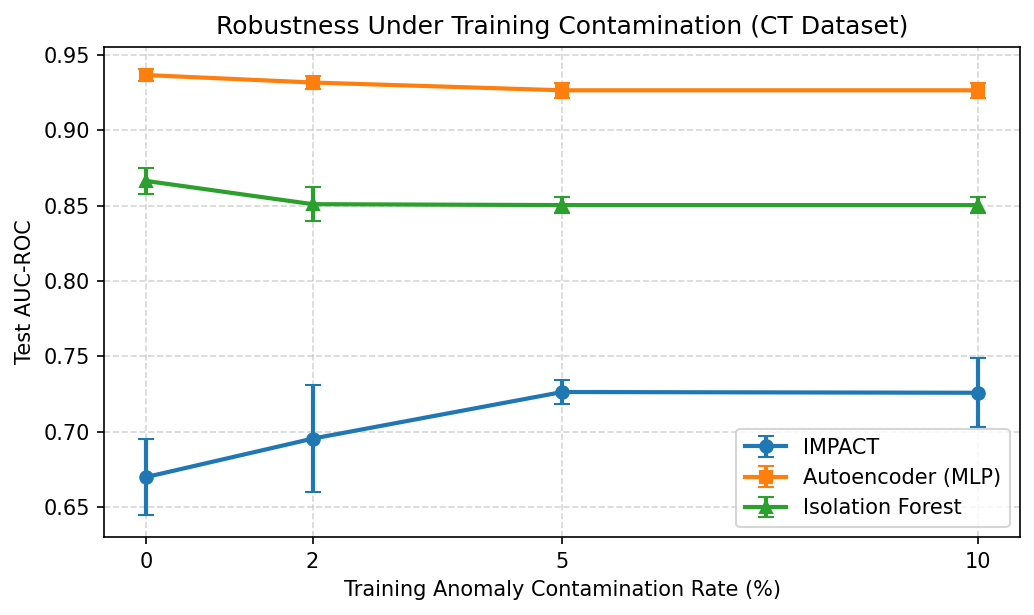

In [9]:
import matplotlib.pyplot as plt
import numpy as np

print("=== Experiment 2 Summary: Contamination Stress Test on CT ===")
for i, rate in enumerate(contam_rates):
    print(f"Contam {int(rate*100):2d}% | "
          f"IMPACT: {contam_results['IMPACT']['mean'][i]:.4f} +/- {contam_results['IMPACT']['std'][i]:.4f} | "
          f"AE: {contam_results['Autoencoder (MLP)']['mean'][i]:.4f} +/- {contam_results['Autoencoder (MLP)']['std'][i]:.4f} | "
          f"IF: {contam_results['Isolation Forest']['mean'][i]:.4f} +/- {contam_results['Isolation Forest']['std'][i]:.4f}")

plt.figure(figsize=(7, 4.2), dpi=150)
x_pct = [int(r * 100) for r in contam_rates]
for m, marker in [('IMPACT', 'o'), ('Autoencoder (MLP)', 's'), ('Isolation Forest', '^')]:
    plt.errorbar(x_pct, contam_results[m]['mean'], yerr=contam_results[m]['std'], marker=marker, linewidth=2, capsize=4, label=m)
plt.xlabel('Training Anomaly Contamination Rate (%)')
plt.ylabel('Test AUC-ROC')
plt.title('Robustness Under Training Contamination (CT Dataset)')
plt.xticks(x_pct)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig('/content/ct_contamination_comparison.png')
plt.show()